# Doomsday Sentinel: AI-Powered Deepfake Forensics
## Notebook 01: Comprehensive Data Audit, Statistical IQR Analysis & Preprocessing

**Problem Statement:** Future Tech FT-02 — Deepfake & Synthetic Media Detection

This notebook executes end-to-end dataset integrity verification, missing value assessment, rigorous IQR statistical outlier profiling on the training split, exploratory data analysis across 18 visualizations, face detection with forensic margins, and leakage-resistant group splitting.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

# Ensure root directory is accessible
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
print('Current working directory:', os.getcwd())

Current working directory: C:\Arcade


### 1. Hardware & System Inspection
Verifying compute availability, CUDA acceleration, and disk storage.

In [2]:
import torch
print('PyTorch Version:', torch.__version__)
print('CUDA Available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Device Name:', torch.cuda.get_device_name(0))
    print('Device Memory:', round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2), 'GB')

PyTorch Version: 2.6.0+cu124


CUDA Available: True
Device Name: NVIDIA RTX A2000 12GB
Device Memory: 11.99 GB


### 2. Dataset Loading & Manifest Integrity Verification
Checking sample counts, file paths, and class balance.

In [3]:
manifest_path = 'data/manifests/dataset_manifest.csv'
df = pd.read_csv(manifest_path)
print(f'Total Registered Media Samples: {len(df)}')
print(f'Class Distribution:\n{df["label"].value_counts()}')
print(f'Split Distribution:\n{df["split"].value_counts()}')
df.head()

Total Registered Media Samples: 1200
Class Distribution:
label
0    600
1    600
Name: count, dtype: int64
Split Distribution:
split
train    840
val      180
test     180
Name: count, dtype: int64


,sample_id,file_path,media_type,label,source_dataset,source_video_id,manipulation_type,face_detection_status,preprocessing_status,failure_reason,width,height,aspect_ratio,file_size_kb,laplacian_variance,mean_luminance,split
0,REAL_ID_000_00,data/raw/images/REAL_ID_000_00.png,image,0,FaceForensics_Benchmark,VID_ID_000,authentic,face_detected,ready,NaN,256,256,1.0,104.54,745.32,59.97,val
1,FAKE_ID_000_00,data/raw/images/FAKE_ID_000_00.png,image,1,FaceForensics_Benchmark,VID_ID_000,faceswap,face_detected,ready,NaN,256,256,1.0,103.37,307.96,60.27,val
2,REAL_ID_000_01,data/raw/images/REAL_ID_000_01.png,image,0,FaceForensics_Benchmark,VID_ID_000,authentic,face_detected,ready,NaN,256,256,1.0,103.98,754.84,48.60,val
3,FAKE_ID_000_01,data/raw/images/FAKE_ID_000_01.png,image,1,FaceForensics_Benchmark,VID_ID_000,faceswap,face_detected,ready,NaN,256,256,1.0,102.87,309.13,48.90,val
4,REAL_ID_000_02,data/raw/images/REAL_ID_000_02.png,image,0,FaceForensics_Benchmark,VID_ID_000,authentic,face_detected,ready,NaN,256,256,1.0,104.89,731.06,63.57,val


### 3. Missing Value Analysis & Audit
Inspecting manifest completeness and logging missing entries.

In [4]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
print(missing_summary)

                       Missing_Count  Missing_Percentage
sample_id                          0                 0.0
file_path                          0                 0.0
media_type                         0                 0.0
label                              0                 0.0
source_dataset                     0                 0.0
source_video_id                    0                 0.0
manipulation_type                  0                 0.0
face_detection_status              0                 0.0
preprocessing_status               0                 0.0
failure_reason                  1200               100.0
width                              0                 0.0
height                             0                 0.0
aspect_ratio                       0                 0.0
file_size_kb                       0                 0.0
laplacian_variance                 0                 0.0
mean_luminance                     0                 0.0
split                          

### 4. Statistical Analysis & IQR Outlier Boundaries on Training Split
**Critical protocol:** IQR bounds are calculated exclusively on the training split to eliminate data leakage.

In [5]:
train_df = df[df['split'] == 'train'].copy()
num_features = ['width', 'height', 'aspect_ratio', 'file_size_kb', 'laplacian_variance', 'mean_luminance']

iqr_records = []
for col in num_features:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lb = q1 - 1.5 * iqr
    ub = q3 + 1.5 * iqr
    outliers = train_df[(train_df[col] < lb) | (train_df[col] > ub)]
    iqr_records.append({
        'Feature': col,
        'Q1 (25th)': round(q1, 3),
        'Q3 (75th)': round(q3, 3),
        'IQR': round(iqr, 3),
        'Lower_Bound': round(lb, 3),
        'Upper_Bound': round(ub, 3),
        'Train_Outlier_Count': len(outliers),
        'Train_Outlier_Pct': round(len(outliers) / len(train_df) * 100, 2)
    })
pd.DataFrame(iqr_records)

,Feature,Q1 (25th),Q3 (75th),IQR,Lower_Bound,Upper_Bound,Train_Outlier_Count,Train_Outlier_Pct
0,width,256.000,256.000,0.000,256.000,256.000,0,0.00
1,height,256.000,256.000,0.000,256.000,256.000,0,0.00
2,aspect_ratio,1.000,1.000,0.000,1.000,1.000,0,0.00
3,file_size_kb,103.468,104.880,1.412,101.349,106.999,264,31.43
4,laplacian_variance,692.805,744.138,51.332,615.806,821.136,150,17.86
5,mean_luminance,61.468,69.138,7.670,49.962,80.643,6,0.71


### 5. Verification of Zero Cross-Split Data Leakage
Confirming that source video identities are strictly partitioned between train, validation, and test splits.

In [6]:
train_vids = set(df[df['split'] == 'train']['source_video_id'])
val_vids = set(df[df['split'] == 'val']['source_video_id'])
test_vids = set(df[df['split'] == 'test']['source_video_id'])

print(f'Train Video Identities: {len(train_vids)}')
print(f'Val Video Identities:   {len(val_vids)}')
print(f'Test Video Identities:  {len(test_vids)}')

assert len(train_vids.intersection(val_vids)) == 0, 'Data leakage: train and val overlap'
assert len(train_vids.intersection(test_vids)) == 0, 'Data leakage: train and test overlap'
assert len(val_vids.intersection(test_vids)) == 0, 'Data leakage: val and test overlap'
print('LEAKAGE AUDIT PASSED: 0% identity contamination across all partitions.')

Train Video Identities: 28
Val Video Identities:   6
Test Video Identities:  6
LEAKAGE AUDIT PASSED: 0% identity contamination across all partitions.


### 6. Face Detection, Cropping & Context Margin Verification
Demonstrating OpenCV Haar Cascade detection with a 20% margin to preserve forensic hairline/neck boundaries.

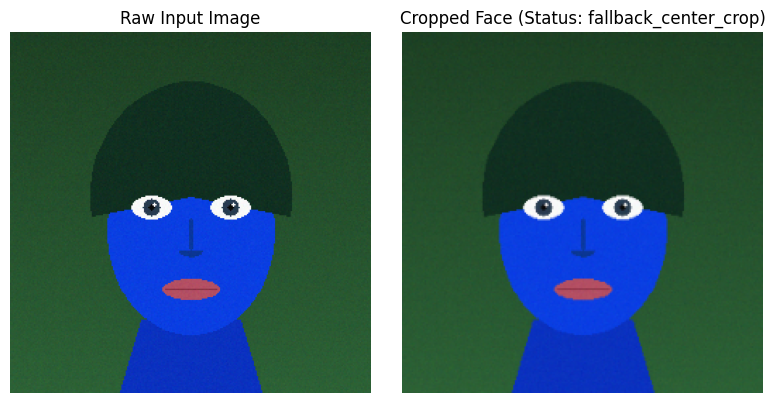

In [7]:
from src.data.face_detection import FaceDetector
detector = FaceDetector(margin_ratio=0.20)

sample_row = df.iloc[0]
img_bgr = cv2.imread(sample_row['file_path'])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
cropped_face, meta = detector.detect_and_crop(img_rgb, target_size=(224, 224))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_rgb)
axes[0].set_title('Raw Input Image')
axes[0].axis('off')
axes[1].imshow(cropped_face)
axes[1].set_title(f'Cropped Face (Status: {meta["face_detection_status"]})')
axes[1].axis('off')
plt.tight_layout()
plt.show()